# Array and batch validation

Checks `data/processed/xtrend_arrays.npz` and the batches built from it by
`project.vectorization_batching` (settings in `configs/model.json`):

1. The arrays match the processed parquet files.
2. The walk-forward splits: train, val and test don't overlap, and each test day is scored once.
3. One batch: shapes, padding, and a picture of one target with its contexts.
4. Causality: contexts never end after the target's first scored day.

Nothing here writes files, unless the arrays file is missing or out of date, in which case `load_arrays` rebuilds it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("..").resolve() / "src"))
from project import features as F
from project import vectorization_batching as V
from project.data import ROOT

cfg = F.load_config()
mcfg = V.load_model_config(data_cfg=cfg)
a = V.load_arrays(cfg, mcfg)
windows = V.expanding_windows(mcfg)
S = mcfg["sequences"]
L, WARM = S["target_length"], S["warmup_length"]
rng = np.random.default_rng(0)

pd.DataFrame({k: {"shape": v.shape, "dtype": str(v.dtype),
                  "nulls": int(pd.isna(v).sum()) if v.dtype.kind in "fM" else 0}
              for k, v in a.items()}).T

,shape,dtype,nulls
inputs,"(362675, 8)",float32,0
target,"(362675,)",float32,0
next_ret,"(362675,)",float32,0
sigma,"(362675,)",float32,0
date,"(362675,)",datetime64[D],0
next_date,"(362675,)",datetime64[D],0
ticker_id,"(362675,)",int64,0
offset,"(362675,)",int64,0
tickers,"(49,)",<U4,0
input_columns,"(8,)",<U10,0


## 1. Arrays match the source files

In [2]:
feat = (pd.read_parquet(ROOT / cfg["processed_path"])
          .sort_values(["ticker", "date"]).reset_index(drop=True))
raw = pd.read_parquet(ROOT / cfg["raw_path"], columns=["ticker", "date"]).sort_values(["ticker", "date"])
raw["next_date"] = raw.groupby("ticker")["date"].shift(-1)
nxt = feat[["ticker", "date"]].merge(raw, on=["ticker", "date"], how="left")["next_date"]
regimes = pd.read_parquet(ROOT / cfg["regimes_path"])

checks = {
    "same number of rows": len(feat) == len(a["inputs"]),
    "inputs match": np.allclose(a["inputs"], feat[list(a["input_columns"])].to_numpy(np.float32)),
    "target, next_ret, sigma match": all(np.allclose(a[c], feat[c].to_numpy(np.float32))
                                         for c in ["target", "next_ret", "sigma"]),
    "dates match": (a["date"] == feat["date"].to_numpy("datetime64[D]")).all(),
    "tickers match": (a["tickers"][a["ticker_id"]] == feat["ticker"].to_numpy()).all(),
    "next_date = next raw trading day": (a["next_date"] == nxt.to_numpy("datetime64[D]")).all(),
    "next_date after date": (a["next_date"] > a["date"]).all(),
    "offset counts 0, 1, 2, ... per ticker": (a["offset"] == feat.groupby("ticker").cumcount()).all(),
}
for Lr in sorted(regimes["max_length"].unique()):
    s, e = a[f"regimes_{Lr}_start"], a[f"regimes_{Lr}_end"]
    checks[f"regimes {Lr}: one ticker, 5 to {Lr} rows"] = (
        (a["ticker_id"][s] == a["ticker_id"][e]).all() and (e - s + 1 >= 5).all()
        and (e - s + 1 <= Lr).all())
    checks[f"regimes {Lr}: kept {len(e):,} of {(regimes.max_length == Lr).sum():,} "
           "(rest start before the feature sample)"] = len(e) <= (regimes.max_length == Lr).sum()
pd.Series(checks, name="pass").to_frame()

,pass
same number of rows,True
inputs match,True
"target, next_ret, sigma match",True
dates match,True
tickers match,True
next_date = next raw trading day,True
next_date after date,True
"offset counts 0, 1, 2, ... per ticker",True
"regimes 21: one ticker, 5 to 21 rows",True
"regimes 21: kept 19,824 of 20,176 (rest start before the feature sample)",True


## 2. Walk-forward splits

For each window: how many target sequences each split has, how many were **dropped** (too few
contexts before them), and how many rows can't be **scored** (a future's first 63 rows have no
warm-up). Rows are assigned by `next_date`, the day their target is earned.

In [3]:
rows, batchers = [], {}
for i, w in enumerate(windows):
    b = {s: V.Batcher(a, w, s, mcfg, cfg) for s in V.SPLITS}
    batchers[i] = b
    tr, va, te = (b[s].score_rows for s in V.SPLITS)
    hits = np.zeros(len(te), int)
    for k in range(WARM, L):
        np.add.at(hits, b["test"].ends - L + 1 + k, 1)
    rows.append({
        "test": f"{w['test_start']} to {w['test_end']}",
        **{f"{s} seqs": len(b[s]) for s in V.SPLITS},
        **{f"{s} dropped": b[s].dropped for s in V.SPLITS},
        "test unscored": b["test"].unscored,
        "val share": va.sum() / (tr.sum() + va.sum()),
        "splits disjoint": not ((tr & va).any() or (tr & te).any() or (va & te).any()),
        "train/val before test": a["next_date"][tr | va].max() < w["test_start"],
        "test days scored once": hits[te].max() == 1,
    })
pd.DataFrame(rows).style.format({"val share": "{:.1%}"})

,test,train seqs,val seqs,test seqs,train dropped,val dropped,test dropped,test unscored,val share,splits disjoint,train/val before test,test days scored once
0,1995-01-01 to 2000-01-01,31542,3967,682,0,0,0,667,10.0%,True,True,True
1,2000-01-01 to 2005-01-01,69150,8201,865,0,0,0,383,10.0%,True,True,True
2,2005-01-01 to 2010-01-01,117146,13644,945,0,0,0,373,10.0%,True,True,True
3,2010-01-01 to 2015-01-01,169577,19531,995,0,0,0,0,10.0%,True,True,True
4,2015-01-01 to 2020-01-01,224142,25595,955,0,0,0,63,10.0%,True,True,True
5,2020-01-01 to 2024-01-01,277814,31574,755,0,0,0,0,10.0%,True,True,True


Rows per split over time for one future (window 2): train, then the last 10% as val, then test.

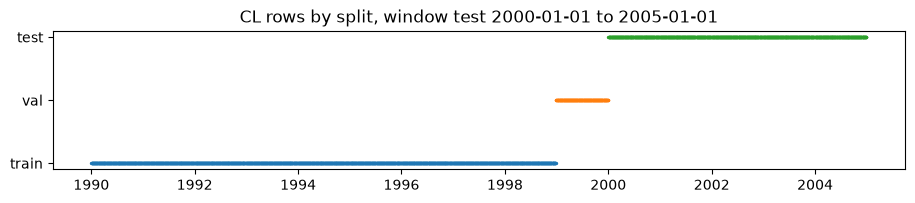

In [4]:
w = windows[1]
tid = int(np.flatnonzero(a["tickers"] == "CL")[0])
fig, ax = plt.subplots(figsize=(11, 1.8))
for y, (s, col) in enumerate(zip(V.SPLITS, ["tab:blue", "tab:orange", "tab:green"])):
    r = batchers[1][s].score_rows & (a["ticker_id"] == tid)
    ax.scatter(a["date"][r], np.full(r.sum(), y), s=2, color=col, label=s)
ax.set_yticks(range(3), V.SPLITS)
ax.set_title(f"CL rows by split, window test {w['test_start']} to {w['test_end']}")
plt.show()

## 3. One batch

Shapes for a training batch of 64. `context_x` is (batch, contexts, context length, inputs);
CPD contexts shorter than the maximum are padded with zeros at the front.

In [5]:
b = batchers[len(windows) - 1]["train"]
batch = next(b.batches(64, rng))
print(pd.Series({k: v.shape for k, v in batch.items()}).to_string())
m = batch["context_mask"]
lens = m.sum(-1)
print(f"\npadding is all zeros: {(batch['context_x'][~m] == 0).all() and (batch['context_y'][~m] == 0).all()}")
print(f"padding only at the front: {(np.diff(m.astype(int), axis=-1) >= 0).all()}")
print(f"context lengths: min {lens.min()}, mean {lens.mean():.1f}, max {lens.max()}")
print(f"score_mask: first {WARM} positions never scored: {not batch['score_mask'][:, :WARM].any()}")

x                       (64, 126, 8)
y                          (64, 126)
next_ret                   (64, 126)
sigma                      (64, 126)
score_mask                 (64, 126)
ticker_id                      (64,)
date                       (64, 126)
context_x            (64, 10, 21, 8)
context_y               (64, 10, 21)
context_mask            (64, 10, 21)
context_ticker_id           (64, 10)

padding is all zeros: True
padding only at the front: True
context lengths: min 6, mean 15.4, max 21
score_mask: first 63 positions never scored: True


One target sequence and its context set. Each bar is one context (a CPD regime). Every context must
end before the target's first scored day (dashed line), so its last next-day return is already known.

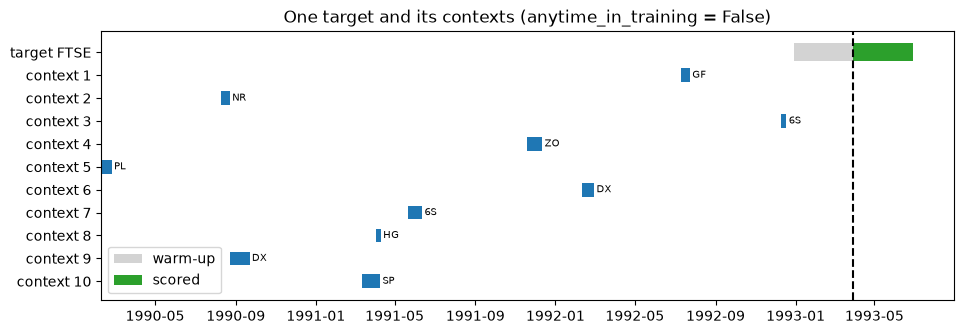

1,369 regimes end before 1993-03-29; contexts end on: 1991-06-11, 1992-12-17, 1990-09-21, 1992-02-28, 1992-07-23, 1991-04-09, 1990-08-22, 1990-02-23, 1991-04-08, 1991-12-11


In [6]:
idx = int(rng.integers(len(b)))                      # one target sequence of this split
e = b.ends[idx]
d = a["date"][e - L + 1:e + 1]
first_scored = d[WARM]
k = V._sample_distinct(b.n_avail[[idx]], b.size, rng)[0]   # its context set, as batch() draws it
cs, ce = b.ctx_start[k], b.ctx_end[k]

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.barh(0, d[-1] - d[0], left=d[0], color="lightgray", label="warm-up")
ax.barh(0, d[-1] - first_scored, left=first_scored, color="tab:green", label="scored")
for i, (s, e_) in enumerate(zip(cs, ce), start=1):
    ax.barh(i, a["date"][e_] - a["date"][s] + np.timedelta64(1, "D"), left=a["date"][s],
            color="tab:blue", height=0.6)
    ax.text(a["date"][e_], i, " " + a["tickers"][a["ticker_id"][e_]], va="center", fontsize=7)
ax.axvline(first_scored, ls="--", color="k")
ax.set_yticks(range(len(k) + 1), [f"target {a['tickers'][a['ticker_id'][e]]}"] +
              [f"context {i}" for i in range(1, len(k) + 1)])
ax.invert_yaxis()
ax.legend(loc="lower left")
ax.set_title("One target and its contexts (anytime_in_training = "
             f"{mcfg['context']['anytime_in_training']})")
plt.show()
print(f"{b.n_avail[idx]:,} regimes end before {first_scored}; contexts end on: "
      + ", ".join(str(a['date'][x]) for x in sorted(ce)))

## 4. Causality and context checks

For every target in every split of every window, draw a context set and check:
- each context ends before the target's first scored day (always at test time, and in training while `anytime_in_training` is false);
- train/val contexts come only from train rows;
- no context is repeated within a set.

In [7]:
rows = []
for i, w in enumerate(windows):
    for s in V.SPLITS:
        b = batchers[i][s]
        k = V._sample_distinct(b.n_avail, b.size, rng)
        ce = b.ctx_end[k]
        first = a["date"][b.ends - L + 1 + WARM]
        strict = s == "test" or not mcfg["context"]["anytime_in_training"]
        allowed = batchers[i]["train"].score_rows if s != "test" else np.ones(len(a["date"]), bool)
        rows.append({"test": str(w["test_start"])[:4], "split": s, "targets": len(b),
                     "ends before first scored day": (a["next_date"][ce] <= first[:, None]).all()
                                                      if strict else "not required",
                     "from allowed rows": allowed[ce].all(),
                     "no repeats": not V._duplicates(k).any()})
pd.DataFrame(rows)

,test,split,targets,ends before first scored day,from allowed rows,no repeats
0,1995,train,31542,True,True,True
1,1995,val,3967,True,True,True
2,1995,test,682,True,True,True
3,2000,train,69150,True,True,True
4,2000,val,8201,True,True,True
5,2000,test,865,True,True,True
6,2005,train,117146,True,True,True
7,2005,val,13644,True,True,True
8,2005,test,945,True,True,True
9,2010,train,169577,True,True,True
